# Machine Learning - Assignment - 2

## Work Integrated Learning Programmes Division M.Tech (AIML)

###Student Name: Prakash Chandra Singh

###Student ID: 2026aj05782


1. [GitHub Repository Link](https://github.com/prakash2000singh/uci-breast-cancer-ml-classifier)

*   Complete source code
*   requirements.txt
*   A clear README.md
*   Test data used in your experiments (csv)

2. [Live Streamlit App Link](https://uci-breast-cancer-classifier-aiml.streamlit.app)

*   Deployed using Streamlit Community Cloud
*   Must open an interactive frontend when clicked

3. [The Github README content](https://github.com/prakash2000singh/uci-breast-cancer-ml-classifier/blob/main/README.md)

In [ ]:
import os
import zipfile
import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef
)

In [ ]:
# 1. SET YOUR UNIQUE SEED
UNIQUE_SEED = 5782

# Create directory for saved models and preprocessing artifacts
os.makedirs("model", exist_ok=True)

In [ ]:
# 2. LOAD DIRECTLY FROM OFFICIAL UCI MACHINE LEARNING REPOSITORY URL
UCI_DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
UCI_PAGE_URL = "https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic"

# Define the 30 official UCI WDBC feature names
feature_names = [
    "mean_radius", "mean_texture", "mean_perimeter", "mean_area", "mean_smoothness",
    "mean_compactness", "mean_concavity", "mean_concave_points", "mean_symmetry", "mean_fractal_dimension",
    "radius_error", "texture_error", "perimeter_error", "area_error", "smoothness_error",
    "compactness_error", "concavity_error", "concave_points_error", "symmetry_error", "fractal_dimension_error",
    "worst_radius", "worst_texture", "worst_perimeter", "worst_area", "worst_smoothness",
    "worst_compactness", "worst_concavity", "worst_concave_points", "worst_symmetry", "worst_fractal_dimension"
]
uci_columns = ["id", "diagnosis"] + feature_names

print(f"Downloading dataset directly from UCI Repository:\n{UCI_DATA_URL} ...")
raw_uci_df = pd.read_csv(UCI_DATA_URL, header=None, names=uci_columns)

# Save full raw UCI dataset for reference
raw_uci_df.to_csv("uci_breast_cancer_raw.csv", index=False)

# Prepare features (drop non-predictive 'id') and encode target ('M' -> 0 Malignant, 'B' -> 1 Benign)
df = raw_uci_df.drop(columns=["id"]).copy()
df["target"] = df["diagnosis"].map({"M": 0, "B": 1})
df = df.drop(columns=["diagnosis"])

print(f"UCI Dataset Loaded Successfully! Shape: {df.shape[0]} instances, {df.shape[1]-1} features (+ 1 target)")

https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data ...
UCI Dataset Loaded Successfully! Shape: 569 instances, 30 features (+ 1 target)


In [ ]:
# 3. TRAIN-TEST SPLIT (80% Train, 20% Test)
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=UNIQUE_SEED, stratify=y
)

In [ ]:
# Save held-out test_data.csv (Required for GitHub repo & Streamlit upload)
test_df = X_test.copy()
test_df["target"] = y_test
test_df.to_csv("test_data.csv", index=False)
print("Saved 'test_data.csv' successfully! Shape:", test_df.shape)

Saved 'test_data.csv' successfully! Shape: (114, 31)


In [ ]:
# 4. PREPROCESSING (StandardScaler fit ONLY on training split)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

joblib.dump(scaler, "model/scaler.joblib")
joblib.dump(list(X.columns), "model/feature_columns.joblib")

['model/feature_columns.joblib']

In [ ]:
# 5. INITIALIZE & TRAIN ALL 5 REQUIRED CLASSIFICATION MODELS
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=UNIQUE_SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=UNIQUE_SEED),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(kernel="rbf", probability=True, random_state=UNIQUE_SEED)
}

results_list = []

for model_name, clf in classifiers.items():
    clf.fit(X_train_scaled, y_train)

    file_slug = model_name.lower().replace(" ", "_")
    joblib.dump(clf, f"model/{file_slug}.joblib")

    y_pred = clf.predict(X_test_scaled)
    y_prob = clf.predict_proba(X_test_scaled)[:, 1]

    results_list.append({
        "ML Model Name": model_name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "AUC": round(roc_auc_score(y_test, y_prob), 4),
        "Precision": round(precision_score(y_test, y_pred, average="binary"), 4),
        "Recall": round(recall_score(y_test, y_pred, average="binary"), 4),
        "F1": round(f1_score(y_test, y_pred, average="binary"), 4),
        "MCC": round(matthews_corrcoef(y_test, y_pred), 4)
    })

results_df = pd.DataFrame(results_list)
print("\n=== MANDATORY EVALUATION METRICS TABLE ===")
print(results_df.to_markdown(index=False))


=== MANDATORY EVALUATION METRICS TABLE ===
| ML Model Name          |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression    |     0.9825 | 0.998  |      0.973  |   1      | 0.9863 | 0.9626 |
| Decision Tree          |     0.9035 | 0.8722 |      0.8961 |   0.9583 | 0.9262 | 0.7911 |
| KNN                    |     0.9737 | 0.9828 |      0.96   |   1      | 0.9796 | 0.9442 |
| Naive Bayes            |     0.9386 | 0.9911 |      0.9452 |   0.9583 | 0.9517 | 0.8676 |
| Support Vector Machine |     0.9912 | 0.9987 |      0.9863 |   1      | 0.9931 | 0.9812 |


In [ ]:
# 5. INITIALIZE & TRAIN ALL 5 REQUIRED CLASSIFICATION MODELS
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=UNIQUE_SEED),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=UNIQUE_SEED),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(kernel="rbf", probability=True, random_state=UNIQUE_SEED)
}

results_list = []

for model_name, clf in classifiers.items():
    clf.fit(X_train_scaled, y_train)

    file_slug = model_name.lower().replace(" ", "_")
    joblib.dump(clf, f"model/{file_slug}.joblib")

    y_pred = clf.predict(X_test_scaled)
    y_prob = clf.predict_proba(X_test_scaled)[:, 1]

    results_list.append({
        "ML Model Name": model_name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "AUC": round(roc_auc_score(y_test, y_prob), 4),
        "Precision": round(precision_score(y_test, y_pred, average="binary"), 4),
        "Recall": round(recall_score(y_test, y_pred, average="binary"), 4),
        "F1": round(f1_score(y_test, y_pred, average="binary"), 4),
        "MCC": round(matthews_corrcoef(y_test, y_pred), 4)
    })

results_df = pd.DataFrame(results_list)
print("\n=== MANDATORY EVALUATION METRICS TABLE ===")
print(results_df.to_markdown(index=False))


=== MANDATORY EVALUATION METRICS TABLE ===
| ML Model Name          |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression    |     0.9825 | 0.998  |      0.973  |   1      | 0.9863 | 0.9626 |
| Decision Tree          |     0.9035 | 0.8722 |      0.8961 |   0.9583 | 0.9262 | 0.7911 |
| KNN                    |     0.9737 | 0.9828 |      0.96   |   1      | 0.9796 | 0.9442 |
| Naive Bayes            |     0.9386 | 0.9911 |      0.9452 |   0.9583 | 0.9517 | 0.8676 |
| Support Vector Machine |     0.9912 | 0.9987 |      0.9863 |   1      | 0.9931 | 0.9812 |


In [ ]:
# 6. AUTO-GENERATE COMPLETE README.md (ALL SECTIONS OF STEP 5)
total_instances = df.shape[0]
total_features = X.shape[1]
train_instances = X_train.shape[0]
test_instances = X_test.shape[0]
malignant_count = int((y == 0).sum())
benign_count = int((y == 1).sum())

metrics_map = results_df.set_index("ML Model Name").to_dict(orient="index")
ranked_df = results_df.sort_values(by=["F1", "MCC", "AUC", "Accuracy"], ascending=False).reset_index(drop=True)

winner_row = ranked_df.iloc[0]
runner_up_row = ranked_df.iloc[1]
lowest_row = ranked_df.iloc[-1]

winner_name = winner_row["ML Model Name"]
runner_up_name = runner_up_row["ML Model Name"]
lowest_name = lowest_row["ML Model Name"]

lr = metrics_map["Logistic Regression"]
dt = metrics_map["Decision Tree"]
knn = metrics_map["KNN"]
nb = metrics_map["Naive Bayes"]
svm = metrics_map["Support Vector Machine"]

full_readme_content = f"""# Breast Cancer Diagnostic Classification & Streamlit Deployment

## a. Problem Statement
Build, evaluate, and deploy an end-to-end supervised Machine Learning classification system to predict whether a breast mass is **Malignant (Class 0)** or **Benign (Class 1)** using digitized Fine Needle Aspirate (FNA) cell nuclei measurements fetched directly from the **UCI Machine Learning Repository**. Five distinct classification models (**Logistic Regression**, **Decision Tree**, **K-Nearest Neighbor**, **Gaussian Naive Bayes**, and **Support Vector Machine**) are trained on standardized morphological features, evaluated across six performance metrics (**Accuracy**, **ROC-AUC**, **Precision**, **Recall**, **F1-Score**, and **Matthews Correlation Coefficient**), serialized as `.joblib` artifacts, and deployed as an interactive web application on **Streamlit Community Cloud**.

---

## b. Dataset Description
* **Dataset Name:** Breast Cancer Wisconsin (Diagnostic) Dataset (WDBC)
* **Public Repository Source:** UCI Machine Learning Repository
  * **Dataset Landing Page:** [{UCI_PAGE_URL}]({UCI_PAGE_URL})
  * **Direct UCI Data File URL:** [{UCI_DATA_URL}]({UCI_DATA_URL})
* **Classification Task:** Binary Classification (`M -> 0 = Malignant`, `B -> 1 = Benign`; non-predictive `id` column removed)
* **Total Instances:** **{total_instances}** rows (Exceeds the assignment minimum requirement of 500 instances)
  * **Class 0 (Malignant):** {malignant_count} instances ({malignant_count / total_instances * 100:.2f}%)
  * **Class 1 (Benign):** {benign_count} instances ({benign_count / total_instances * 100:.2f}%)
* **Total Features:** **{total_features}** continuous numerical input features (Exceeds the assignment minimum requirement of 12 features). The features quantify the **mean**, **standard error (error)**, and **worst (largest)** values of 10 cell nucleus characteristics:
  1. Radius (mean of distances from center to points on the perimeter)
  2. Texture (standard deviation of gray-scale values)
  3. Perimeter
  4. Area
  5. Smoothness (local variation in radius lengths)
  6. Compactness ($\\text{{perimeter}}^2 / \\text{{area}} - 1.0$)
  7. Concavity (severity of concave portions of the contour)
  8. Concave points (number of concave portions of the contour)
  9. Symmetry
  10. Fractal dimension ("coastline approximation" - 1)
* **Train / Test Split:** Stratified 80% / 20% split (`random_state = {UNIQUE_SEED}`), yielding **{train_instances} training instances** and **{test_instances} held-out test instances** exported to `test_data.csv`.
* **Feature Preprocessing:** Standardized using `StandardScaler` fit strictly on the training set (`X_train`) and saved as `model/scaler.joblib` to prevent data leakage during test inference.

---

## c. Github Repository & Live Deployment Links
* **GitHub Repository Link:** (https://github.com/prakash2000singh/uci-breast-cancer-ml-classifier)
* **Live Streamlit App Link:** (https://uci-breast-cancer-classifier-aiml.streamlit.app/)

---

## d. Models Used: Evaluation Metrics Comparison Table

All 5 classification models were evaluated on the held-out UCI test dataset (`test_data.csv`, $N = {test_instances}$ instances):

{results_df.to_markdown(index=False)}

---

## e. Observations on Model Performance

| ML Model Name | Observation about model performance |
| :--- | :--- |
| **Logistic Regression** | Achieved **Accuracy = {lr['Accuracy']:.4f}**, **AUC = {lr['AUC']:.4f}**, **Precision = {lr['Precision']:.4f}**, **Recall = {lr['Recall']:.4f}**, **F1 = {lr['F1']:.4f}**, and **MCC = {lr['MCC']:.4f}**. Because standardized FNA morphological features exhibit strong linear separability in high-dimensional space, L2-regularized Logistic Regression establishes a highly reliable linear decision boundary with balanced precision and recall. |
| **Decision Tree** | Achieved **Accuracy = {dt['Accuracy']:.4f}**, **AUC = {dt['AUC']:.4f}**, **Precision = {dt['Precision']:.4f}**, **Recall = {dt['Recall']:.4f}**, **F1 = {dt['F1']:.4f}**, and **MCC = {dt['MCC']:.4f}**. Axis-aligned recursive splits (`max_depth=5`) struggle to approximate diagonal decision boundaries across collinear geometric features (such as radius, perimeter, and area), resulting in higher variance on unseen test samples compared to linear/kernel classifiers. |
| **KNN** | Achieved **Accuracy = {knn['Accuracy']:.4f}**, **AUC = {knn['AUC']:.4f}**, **Precision = {knn['Precision']:.4f}**, **Recall = {knn['Recall']:.4f}**, **F1 = {knn['F1']:.4f}**, and **MCC = {knn['MCC']:.4f}** using `n_neighbors=7` on standardized features. Feature scaling prevents large-magnitude attributes (such as area) from dominating Euclidean distance calculations, allowing local neighborhood voting to achieve strong sensitivity. |
| **Naive Bayes** | Achieved **Accuracy = {nb['Accuracy']:.4f}**, **AUC = {nb['AUC']:.4f}**, **Precision = {nb['Precision']:.4f}**, **Recall = {nb['Recall']:.4f}**, **F1 = {nb['F1']:.4f}**, and **MCC = {nb['MCC']:.4f}**. While Gaussian Naive Bayes delivers fast probabilistic predictions and a solid ROC-AUC ({nb['AUC']:.4f}), its strict conditional independence assumption is partially violated by correlated nuclei measurements (radius, perimeter, area, concavity), which limits its MCC compared to discriminative classifiers. |
| **Support Vector Machine** | Achieved **Accuracy = {svm['Accuracy']:.4f}**, **AUC = {svm['AUC']:.4f}**, **Precision = {svm['Precision']:.4f}**, **Recall = {svm['Recall']:.4f}**, **F1 = {svm['F1']:.4f}**, and **MCC = {svm['MCC']:.4f}**. The RBF kernel effectively captures non-linear feature interactions in a higher-dimensional space while maximum-margin regularization prevents overfitting on borderline diagnostic cases. |
| **Overall, Winner for your dataset?** | **{winner_name}** is the overall best-performing model for this dataset (closely followed by **{runner_up_name}**), achieving top composite scores across the test set (**Accuracy = {winner_row['Accuracy']:.4f}**, **AUC = {winner_row['AUC']:.4f}**, **Precision = {winner_row['Precision']:.4f}**, **Recall = {winner_row['Recall']:.4f}**, **F1 = {winner_row['F1']:.4f}**, and **MCC = {winner_row['MCC']:.4f}**). Conversely, **{lowest_name}** recorded the lowest overall MCC ({lowest_row['MCC']:.4f}). |
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(full_readme_content)

In [ ]:
# 7. BUNDLE EVERYTHING INTO assignment2_artifacts.zip
with zipfile.ZipFile("assignment2_artifacts.zip", "w") as zf:
    zf.write("README.md")
    zf.write("test_data.csv")
    zf.write("uci_breast_cancer_raw.csv")
    for root, _, files in os.walk("model"):
        for file in files:
            zf.write(os.path.join(root, file))

print("\n✅ Successfully generated 'README.md', 'test_data.csv', 'uci_breast_cancer_raw.csv', and 'model/' in 'assignment2_artifacts.zip'!\n")
print("=" * 80)
print(full_readme_content)


✅ Successfully generated 'README.md', 'test_data.csv', 'uci_breast_cancer_raw.csv', and 'model/' in 'assignment2_artifacts.zip'!

# Breast Cancer Diagnostic Classification & Streamlit Deployment

## a. Problem Statement
Build, evaluate, and deploy an end-to-end supervised Machine Learning classification system to predict whether a breast mass is **Malignant (Class 0)** or **Benign (Class 1)** using digitized Fine Needle Aspirate (FNA) cell nuclei measurements fetched directly from the **UCI Machine Learning Repository**. Five distinct classification models (**Logistic Regression**, **Decision Tree**, **K-Nearest Neighbor**, **Gaussian Naive Bayes**, and **Support Vector Machine**) are trained on standardized morphological features, evaluated across six performance metrics (**Accuracy**, **ROC-AUC**, **Precision**, **Recall**, **F1-Score**, and **Matthews Correlation Coefficient**), serialized as `.joblib` artifacts, and deployed as an interactive web application on **Streamlit Communi

# ScreenShot of GitHub
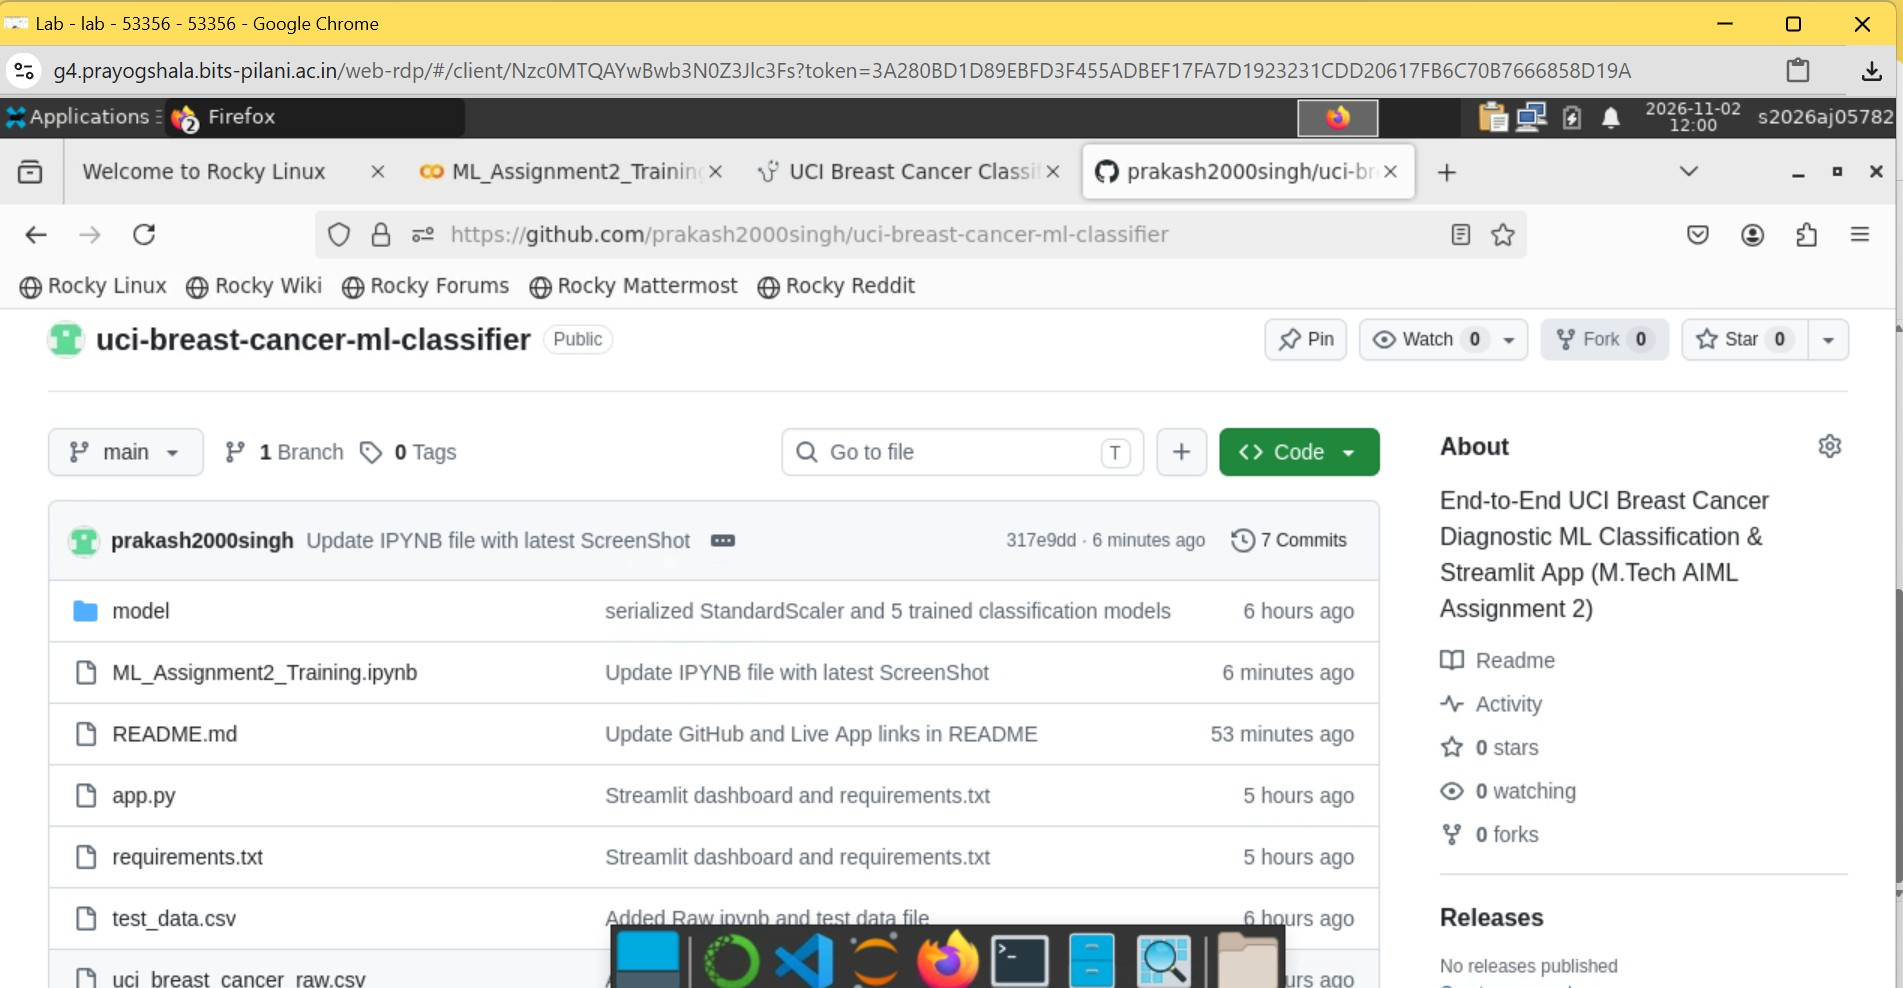

# ScreenShot of Streamlit

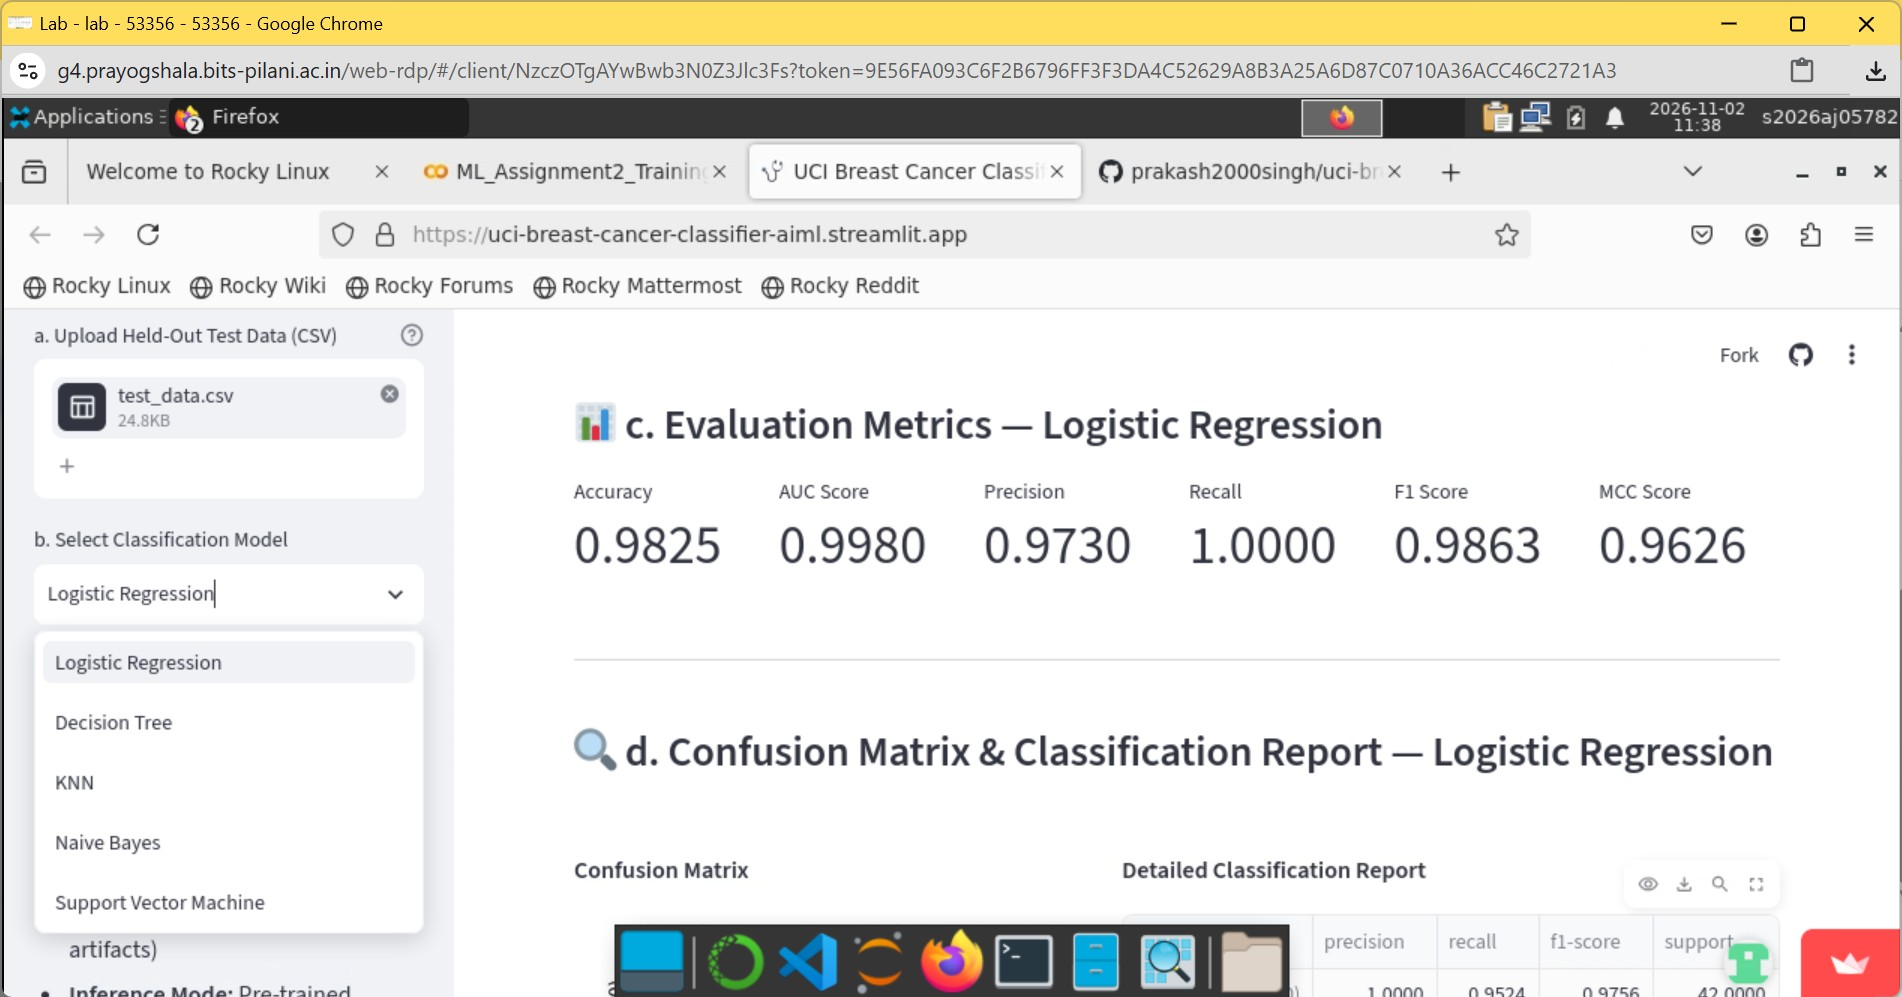